Cette démo reprend en grande partie les [exemples SVM de scikit-learn](https://scikit-learn.org/stable/auto_examples/index.html#support-vector-machines).

Elle est géométrique : elle trace les frontières de décision, les marges et les vecteurs supports, sans jamais mesurer de performance (aucune séparation apprentissage/test). Un SVM s'évalue comme tout classifieur, par validation croisée.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, svm
from sklearn.datasets import make_blobs

# SVM

In [2]:
X = [[0, 0], [1, 1]]
y = [0, 1]
modele = svm.SVC(gamma="auto")
modele.fit(X, y)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## Prédiction


In [3]:
modele.predict([[0.2, 0.2], [-1.0, -1.0], [3.0, 3.0], [0.51, 0.51]])

array([0, 0, 1, 1])

## Les vecteurs supports

On peut récupérer les exemples d'apprentissage qui servent de vecteurs supports :

In [4]:
# Les vecteurs supports
print("vecteurs supports :", modele.support_vectors_)

# Leurs indices dans les données d'apprentissage
print("indices :", modele.support_)

# Leur nombre pour chaque classe
print("nombre par classe :", modele.n_support_)

vecteurs supports : [[0. 0.]
 [1. 1.]]
indices : [0 1]
nombre par classe : [1 1]


## Trouver l'hyperplan séparateur

Ici, on affiche la frontière de décision du SVM appris (trait plein), ses marges (pointillés) et ses vecteurs supports (cerclés).

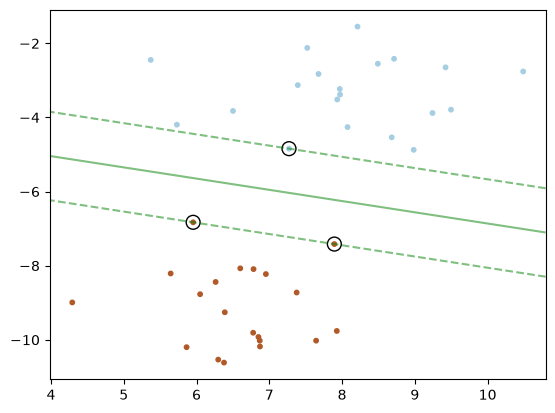

In [5]:
def trace_svm(ax, modele, X, y):
  """Points, frontière (Z = 0), marges (Z = ±1) et vecteurs supports."""
  ax.scatter(X[:, 0], X[:, 1], c=y, s=10, cmap=plt.cm.Paired)

  # Grille qui couvre les points
  xx, yy = np.meshgrid(np.linspace(*ax.get_xlim(), 30), np.linspace(*ax.get_ylim(), 30))
  Z = modele.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

  # Contours pour lesquels Z == -1, Z == 0 et Z == 1
  ax.contour(
    xx, yy, Z, colors="g", levels=[-1, 0, 1], alpha=0.5, linestyles=["--", "-", "--"]
  )
  # Vecteurs supports
  ax.scatter(
    modele.support_vectors_[:, 0],
    modele.support_vectors_[:, 1],
    s=100,
    linewidth=1,
    facecolors="none",
    edgecolors="k",
  )


# 40 points séparables de 2 classes
X, y = make_blobs(n_samples=40, centers=2, random_state=6)

modele = svm.SVC(kernel="linear", C=1)
modele.fit(X, y)

trace_svm(plt.gca(), modele, X, y)
plt.show()

# Marge souple : le paramètre `C`

Quand les classes se chevauchent, aucune droite ne les sépare sans erreur : le SVM tolère des points dans la marge, ou du mauvais côté, contre une pénalité que `C` pondère. `C` grand → marge étroite, peu d'erreurs tolérées (risque de surapprentissage) ; `C` petit → marge large, plus de vecteurs supports. C'est le principal réglage d'un SVM, à choisir par validation croisée.

Ci-dessous, les mêmes nuages que plus haut, plus dispersés, pour trois valeurs de `C`.

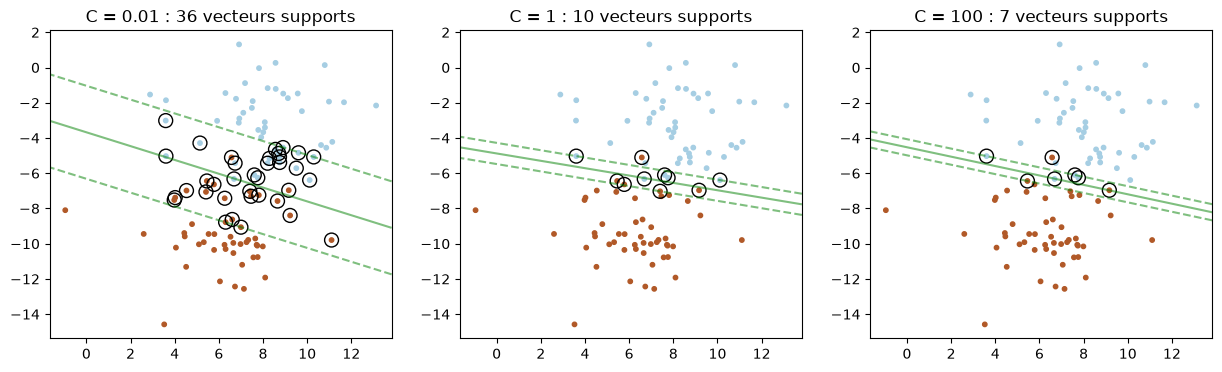

In [6]:
# Les mêmes centres, des nuages qui se chevauchent
X, y = make_blobs(n_samples=100, centers=2, cluster_std=2.0, random_state=6)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, C in zip(axes, [0.01, 1, 100]):
  modele = svm.SVC(kernel="linear", C=C)
  modele.fit(X, y)
  trace_svm(ax, modele, X, y)
  ax.set_title(f"C = {C} : {modele.n_support_.sum()} vecteurs supports")
plt.show()

# Classes déséquilibrées

Avec 1 000 points d'une classe et 100 de l'autre, le SVM sans correction place la frontière au détriment de la petite classe : chaque erreur y coûte autant que dans la grande, et il y en a dix fois moins. `class_weight={0: 1, 1: 10}` rend une erreur sur la classe rare dix fois plus chère, ce qui repousse la frontière vers la grande classe ; `class_weight="balanced"` choisit ces poids d'après les effectifs.

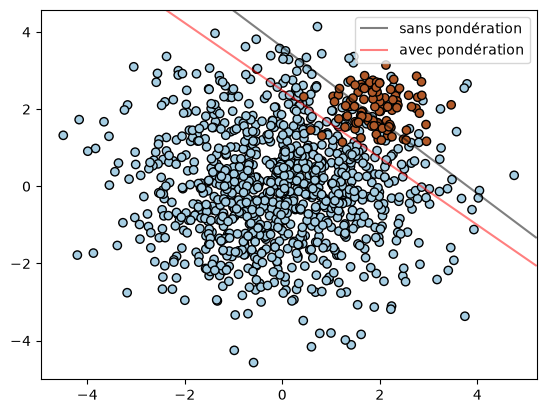

In [7]:
# Deux nuages de 1 000 et 100 points
rng = np.random.RandomState(0)
nb_points_1 = 1000
nb_points_2 = 100
X = np.r_[1.5 * rng.randn(nb_points_1, 2), 0.5 * rng.randn(nb_points_2, 2) + [2, 2]]
y = [0] * (nb_points_1) + [1] * (nb_points_2)

# Le modèle sans correction
modele = svm.SVC(kernel="linear", C=1)
modele.fit(X, y)

# Le modèle qui pondère les erreurs de la petite classe
modele_pondere = svm.SVC(kernel="linear", class_weight={0: 1, 1: 10}, C=1)
modele_pondere.fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolors="k")

# Grille qui couvre les points
ax = plt.gca()
xx, yy = np.meshgrid(np.linspace(*ax.get_xlim(), 30), np.linspace(*ax.get_ylim(), 30))
xy = np.c_[xx.ravel(), yy.ravel()]

# Frontière (Z == 0) de chacun des deux modèles
Z = modele.decision_function(xy).reshape(xx.shape)
a = ax.contour(xx, yy, Z, colors="k", levels=[0], alpha=0.5, linestyles=["-"])
Z = modele_pondere.decision_function(xy).reshape(xx.shape)
b = ax.contour(xx, yy, Z, colors="r", levels=[0], alpha=0.5, linestyles=["-"])

plt.legend(
  [a.legend_elements()[0][0], b.legend_elements()[0][0]],
  ["sans pondération", "avec pondération"],
  loc="upper right",
)
plt.show()

# SVM non linéaire (à noyau)

Pour corser la tâche, on construit un jeu de données à partir d'un XOR : aucune droite ne sépare les deux classes. Le noyau gaussien (RBF, le défaut de `SVC`) trace une frontière courbe ; `gamma` règle la portée de chaque exemple (`gamma="auto"` : 1 / nombre de variables).

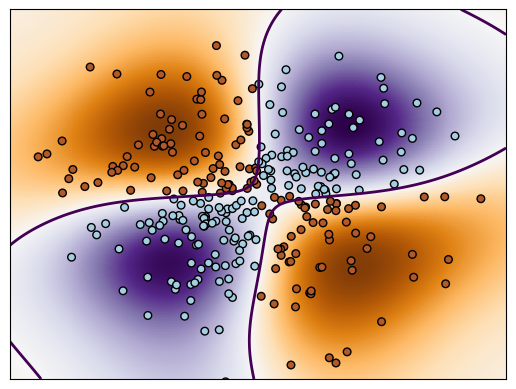

In [8]:
np.random.seed(0)
X = np.random.randn(300, 2)
Y = np.logical_xor(X[:, 0] > 0, X[:, 1] > 0)

# Noyau RBF (le défaut de SVC)
modele = svm.SVC(gamma="auto", kernel="rbf")
modele.fit(X, Y)

# La grille
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
Z = modele.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# La valeur de la fonction de décision, en dégradé de couleur
plt.imshow(
  Z,
  interpolation="nearest",
  extent=(xx.min(), xx.max(), yy.min(), yy.max()),
  aspect="auto",
  origin="lower",
  cmap=plt.cm.PuOr_r,
)
# La frontière, où Z == 0
contours = plt.contour(xx, yy, Z, levels=[0], linewidths=2)
# Les points
plt.scatter(X[:, 0], X[:, 1], s=30, c=Y, cmap=plt.cm.Paired, edgecolors="k")
plt.xticks(())
plt.yticks(())
plt.axis([-3, 3, -3, 3])
plt.show()

# SVM multi-classes

Comparaison de 4 classifieurs SVM (deux linéaires, un à noyau RBF, un à noyau polynomial) sur le jeu de données Iris. On ne garde que ses 2 premières variables :

- la longueur du sépale (*sepal length*) ;
- la largeur du sépale (*sepal width*).

`LinearSVC()` et `SVC(kernel="linear")` donnent des séparations légèrement différentes : ce ne sont pas tout à fait les mêmes modèles.

- `LinearSVC` minimise le carré de la perte charnière (*hinge loss*), `SVC` la perte charnière elle-même ;
- `LinearSVC` régularise aussi la constante (l'ordonnée à l'origine), `SVC` non ;
- `LinearSVC` fait un contre tous, `SVC` un contre un.

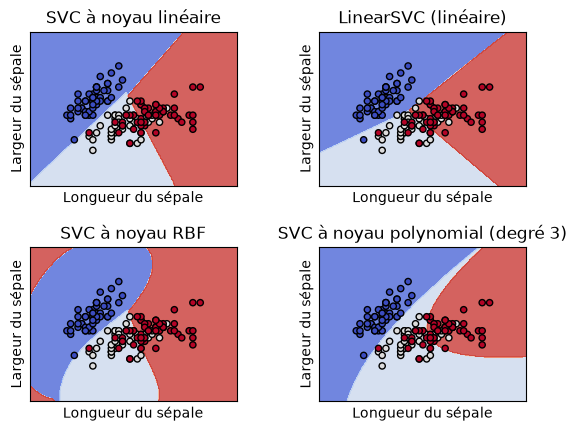

In [9]:
def cree_grille(x, y, h=0.02):
  """Grille de points qui couvre x et y, au pas h."""
  x_min, x_max = x.min() - 1, x.max() + 1
  y_min, y_max = y.min() - 1, y.max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
  return xx, yy


def trace_contours(ax, modele, xx, yy, **params):
  """Colorie la grille (xx, yy) selon la classe que prédit modele."""
  Z = modele.predict(np.c_[xx.ravel(), yy.ravel()])
  Z = Z.reshape(xx.shape)
  return ax.contourf(xx, yy, Z, **params)


# Les 2 premières variables d'Iris
iris = datasets.load_iris()
X = iris.data[:, :2]
y = iris.target

C = 1.0  # Le paramètre de marge souple
modeles = (
  svm.SVC(kernel="linear", C=C, gamma="auto"),
  svm.LinearSVC(C=C, max_iter=20000),
  svm.SVC(kernel="rbf", gamma=0.7, C=C),
  svm.SVC(kernel="poly", gamma="auto", degree=3, C=C),
)
modeles = (modele.fit(X, y) for modele in modeles)

titres = (
  "SVC à noyau linéaire",
  "LinearSVC (linéaire)",
  "SVC à noyau RBF",
  "SVC à noyau polynomial (degré 3)",
)

# Grille de 2 x 2 graphiques
fig, axes = plt.subplots(2, 2)
plt.subplots_adjust(wspace=0.4, hspace=0.4)

X0, X1 = X[:, 0], X[:, 1]
xx, yy = cree_grille(X0, X1)

for modele, titre, ax in zip(modeles, titres, axes.flatten()):
  trace_contours(ax, modele, xx, yy, cmap=plt.cm.coolwarm, alpha=0.8)
  ax.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=20, edgecolors="k")
  ax.set_xlim(xx.min(), xx.max())
  ax.set_ylim(yy.min(), yy.max())
  ax.set_xlabel("Longueur du sépale")
  ax.set_ylabel("Largeur du sépale")
  ax.set_xticks(())
  ax.set_yticks(())
  ax.set_title(titre)

plt.show()